<a href="https://colab.research.google.com/github/nr868848-stack/Customer-Churn-Prediction-ML/blob/main/Customer_Churn_predicti_MLon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.inspection import permutation_importance
import joblib
import os
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Dataset information:
<class 'pandas.core.frame

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())

print("\nBlank TotalCharges values:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

print("\nUnique churn values:")
print(df["Churn"].value_counts(dropna=False))

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate customer IDs:
0

Blank TotalCharges values:
11

Unique churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.drop_duplicates(subset="customerID").copy()

print("Shape after duplicate removal:", df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

display(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())

Shape after duplicate removal: (7043, 21)
Missing TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Churn
0,1,29.85,29.85,No
1,34,56.95,1889.50,No
2,2,53.85,108.15,Yes
3,45,42.30,1840.75,No
4,2,70.70,151.65,Yes


In [ ]:
churn_counts = df["Churn"].value_counts()

churn_rate = (df["Churn"] == "Yes").mean() * 100

print("Customers who stayed:", churn_counts.get("No", 0))
print("Customers who left:", churn_counts.get("Yes", 0))
print(f"Overall churn rate: {churn_rate:.2f}%")

Customers who stayed: 5174
Customers who left: 1869
Overall churn rate: 26.54%


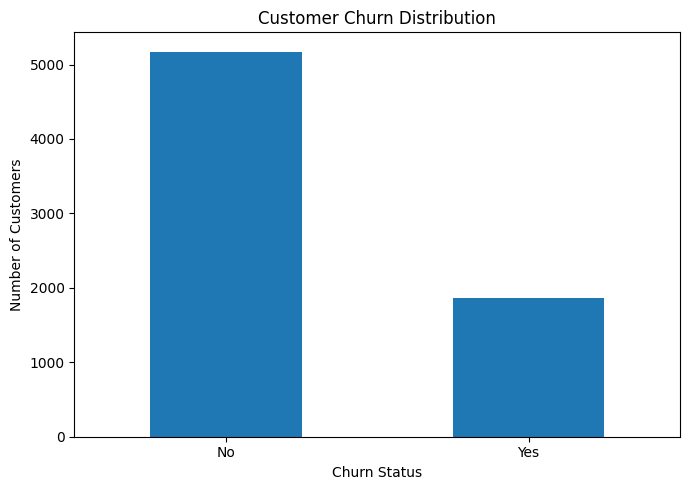

In [ ]:
plt.figure(figsize=(7, 5))
churn_counts.plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn percentage by contract:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


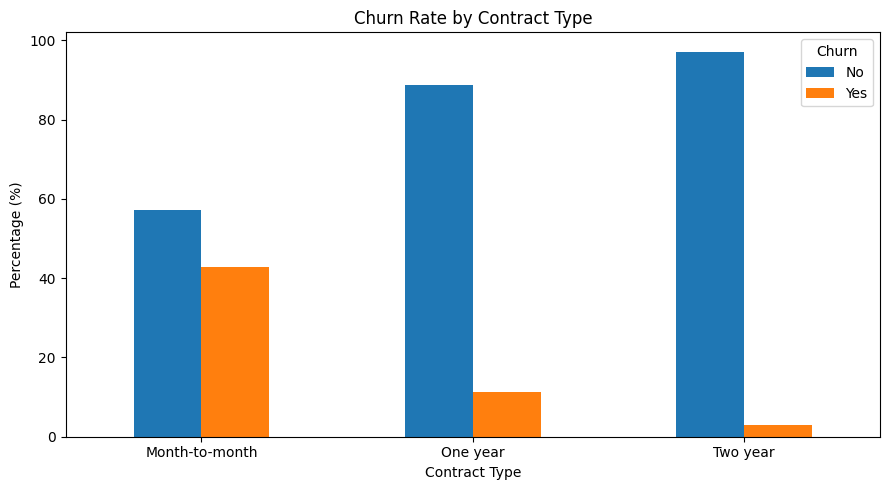

In [ ]:
contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
) * 100

print("Churn percentage by contract:")
display(contract_churn.round(2))

contract_churn.plot(kind="bar", figsize=(9, 5))
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,mean,median,min,max
Churn,,,,
No,37.57,38.0,0,72
Yes,17.98,10.0,1,72


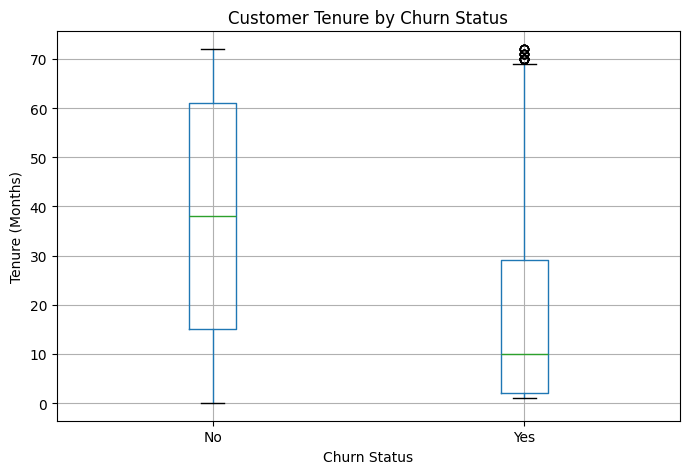

In [ ]:
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["mean", "median", "min", "max"]
)

display(tenure_summary.round(2))

df.boxplot(column="tenure", by="Churn", figsize=(7, 5))
plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

Monthly charges comparison:


,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


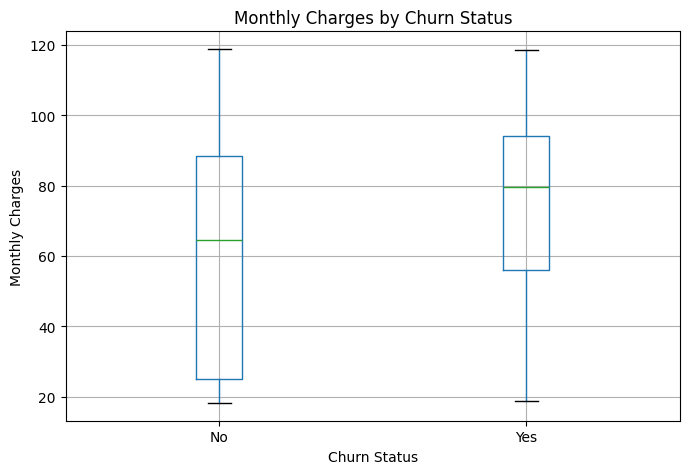

In [ ]:
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
)

print("Monthly charges comparison:")
display(charges_summary.round(2))

df.boxplot(column="MonthlyCharges", by="Churn", figsize=(7, 5))
plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


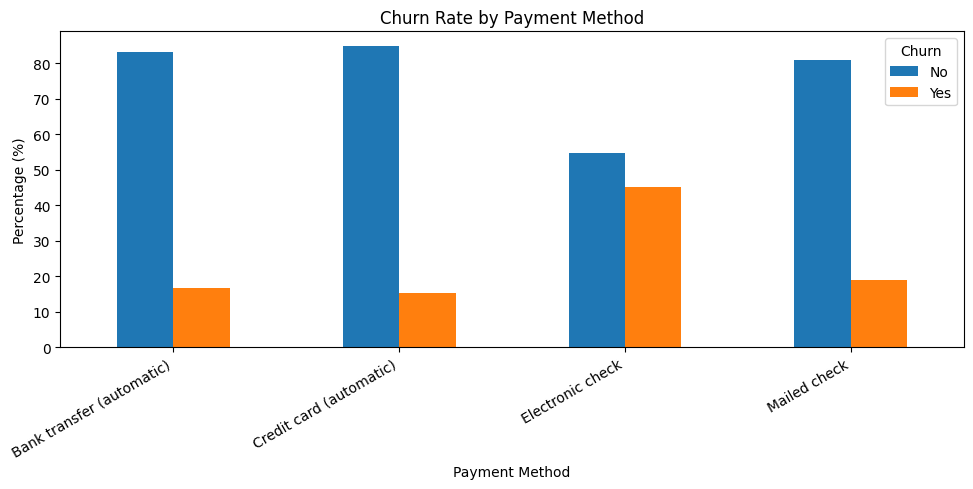

In [ ]:
payment_churn = pd.crosstab(
    df["PaymentMethod"], df["Churn"], normalize="index"
) * 100

display(payment_churn.round(2))

payment_churn.plot(kind="bar", figsize=(10, 5))
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
model_df = df.dropna(subset=["Churn"]).copy()

X = model_df.drop(columns=["Churn", "customerID"])
y = model_df["Churn"].map({"No": 0, "Yes": 1})

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of input features:", X.shape[1])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nTarget distribution:")
print(y.value_counts())

Number of input features: 19
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 5634
Testing rows: 1409
Training churn rate: 26.54 %
Testing churn rate: 26.54 %


In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline ready!")

Preprocessing pipeline ready!


In [ ]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(
    by="ROC AUC", ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Random Forest,0.766,0.546,0.701,0.614,0.840


In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("\nSelection is based on test ROC-AUC.")

Selected model: Logistic Regression

Selection is based on test ROC-AUC.


In [ ]:
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



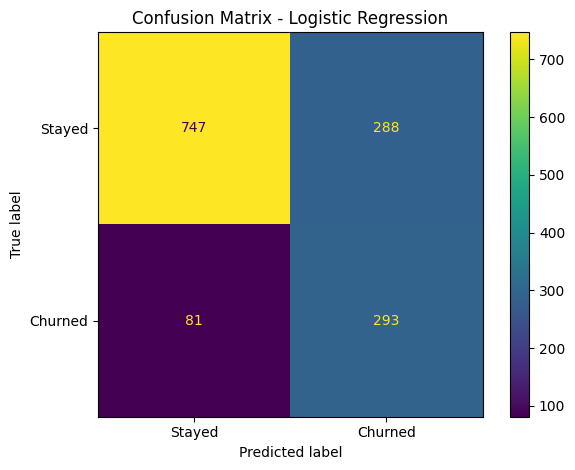

In [ ]:
cm = confusion_matrix(y_test, best_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

display.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

<Figure size 700x500 with 0 Axes>

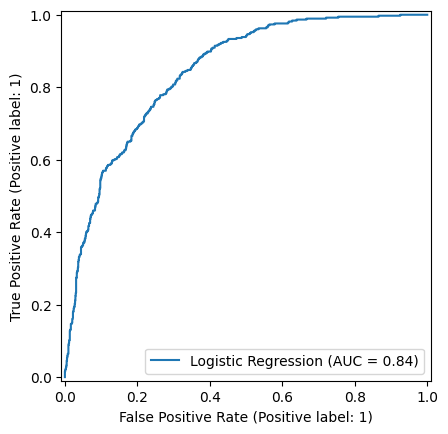

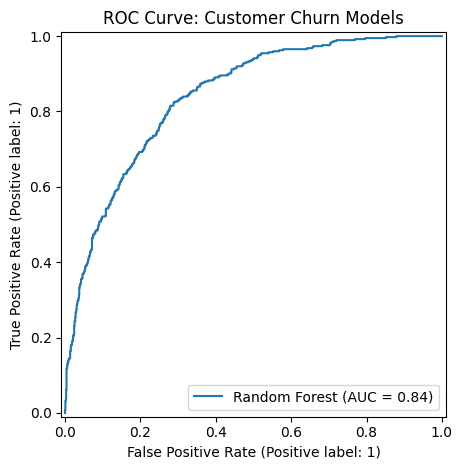

In [ ]:
plt.figure(figsize=(7, 5))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model, X_test, y_test, name=name
    )

plt.title("ROC Curve: Customer Churn Models")
plt.tight_layout()
plt.show()

In [ ]:
cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

print("Cross-validation ROC-AUC scores:")
print(np.round(cv_scores, 3))

print("Mean ROC-AUC:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Cross-validation ROC-AUC scores:
[0.864 0.852 0.851 0.835 0.824]
Mean ROC-AUC: 0.845
Standard deviation: 0.014


,Feature,Importance
4,tenure,0.1520
7,InternetService,0.0433
14,Contract,0.0384
17,MonthlyCharges,0.0370
18,TotalCharges,0.0103
13,StreamingMovies,0.0046
8,OnlineSecurity,0.0041
11,TechSupport,0.0039
12,StreamingTV,0.0039
16,PaymentMethod,0.0033


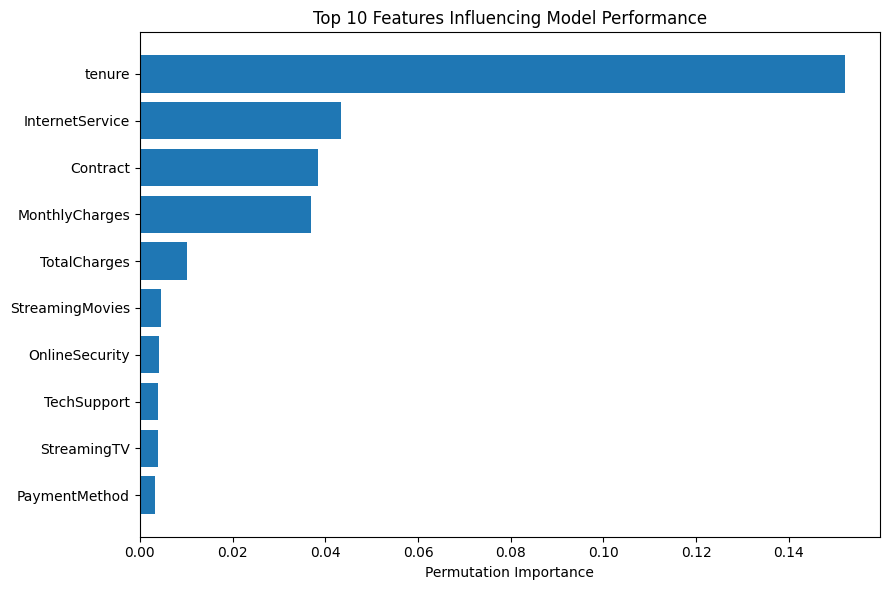

In [ ]:
from IPython.display import display

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance.head(10).round(4))

top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Features Influencing Model Performance")
plt.xlabel("Permutation Importance")
plt.tight_layout()
plt.show()

In [ ]:
sample_customer = X_test.iloc[[0]]

risk_probability = best_model.predict_proba(
    sample_customer
)[0, 1]

risk_prediction = best_model.predict(sample_customer)[0]

print("Sample customer details:")
display(sample_customer)

print(f"Estimated churn probability: {risk_probability:.1%}")

if risk_prediction == 1:
    print("Model prediction: Customer may churn.")
else:
    print("Model prediction: Customer may stay.")

Sample customer details:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


Estimated churn probability: 11.5%
Model prediction: Customer may stay.


In [ ]:
prediction_report = X_test.copy()

prediction_report["Actual_Churn"] = y_test.map({
    0: "No",
    1: "Yes"
}).values

prediction_report["Predicted_Churn"] = pd.Series(
    best_predictions, index=X_test.index
).map({
    0: "No",
    1: "Yes"
})

prediction_report["Churn_Probability"] = best_probabilities
prediction_report["Risk_Level"] = np.where(
    best_probabilities >= 0.60,
    "High",
    np.where(best_probabilities >= 0.35, "Medium", "Low")
)

display(prediction_report.head(10))

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,No,No,0.115472,Low
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,No,Yes,0.853079,High
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,One year,Yes,Credit card (automatic),78.35,3211.20,No,No,0.146831,Low
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,Month-to-month,No,Electronic check,78.20,1468.75,No,Yes,0.660663,High
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,No,No,0.060436,Low
5748,Female,0,No,No,21,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,No,Yes,0.806060,High
3568,Female,0,No,No,21,Yes,No,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40,No,Yes,0.698471,High
2976,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,...,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20,No,No,0.294135,Low
5928,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,...,No internet service,Two year,No,Credit card (automatic),19.75,1311.60,No,No,0.009293,Low
1639,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,Month-to-month,Yes,Electronic check,45.05,770.60,Yes,Yes,0.652555,High


In [ ]:
print("CUSTOMER RETENTION RECOMMENDATIONS")
print("-" * 40)

print("1. Short-tenure customers ke liye onboarding support improve karein.")
print("2. Month-to-month customers ke liye suitable long-term plans test karein.")
print("3. High-risk customers ko customer support se contact karne ka option dein.")
print("4. Monthly charges aur service complaints ko review karein.")
print("5. Retention campaigns ke results ko data se measure karein.")
print("\nRecommendations ko business data se verify karna zaroori hai.")

CUSTOMER RETENTION RECOMMENDATIONS
----------------------------------------
1. Short-tenure customers ke liye onboarding support improve karein.
2. Month-to-month customers ke liye suitable long-term plans test karein.
3. High-risk customers ko customer support se contact karne ka option dein.
4. Monthly charges aur service complaints ko review karein.
5. Retention campaigns ke results ko data se measure karein.

Recommendations ko business data se verify karna zaroori hai.
